# Hospital Readmission Risk: walkthrough

This notebook follows the analysis in order: the SQL feature layer, the clinical scores, the patient-level split, the model comparison, and the capacity and equity results.

Model training takes about five minutes, so it runs in `run_pipeline.py`. This notebook rebuilds the features live and reads the saved results from `outputs/`.

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
from IPython.display import Image, display
from src import config
from src.build_features import build_feature_mart
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 140)

## 1. Build the feature mart in DuckDB

Discharges ending in death or hospice are removed, because those patients cannot be readmitted. Data-quality checks run before anything is returned.

In [2]:
mart = build_feature_mart()
print(f"{mart.attrs['raw_encounters']:,} encounters in source -> {len(mart):,} eligible discharges, "
      f"{mart[config.GROUP].nunique():,} patients, readmission rate {mart[config.TARGET].mean():.1%}")

101,766 encounters in source -> 99,343 eligible discharges, 69,990 patients, readmission rate 11.4%


## 2. Clinical scores built in SQL

The Charlson comorbidity score comes from the three ICD-9 diagnosis codes. LACE adds length of stay, emergency admission, comorbidity and prior emergency visits.

In [3]:
mart.groupby("lace_score")[config.TARGET].agg(discharges="size", readmission_rate="mean").T

lace_score,1.000,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.000,10.000,11.000,12.000,13.000,14.000,15.000,16.000,17.000,19.000
discharges,2348.000,4725.000,6007.000,10608.000,13636.000,12985.000,14046.000,11595.000,9338.000,6870.000,2609.000,2497.000,1590.000,287.000,142.000,41.000,18.000,1.000
readmission_rate,0.065,0.081,0.081,0.091,0.098,0.109,0.119,0.121,0.139,0.148,0.158,0.145,0.171,0.251,0.246,0.293,0.222,0.000


In [4]:
mart.groupby("primary_diagnosis_group")[config.TARGET].agg(discharges="size", readmission_rate="mean") \
    .sort_values("readmission_rate", ascending=False)

,discharges,readmission_rate
primary_diagnosis_group,,
missing,20,0.250
diabetes,8661,0.131
injury,6853,0.124
circulatory,29681,0.117
other,17793,0.117
genitourinary,5002,0.110
neoplasms,3131,0.109
digestive,9333,0.108
respiratory,13934,0.101


## 3. Hold-out results (patients never seen in training)

In [5]:
metrics = json.load(open("../outputs/metrics.json"))
pd.DataFrame(metrics["hold_out"]).T

,auc,average_precision,brier
gradient_boosting,0.675,0.231,0.096
logistic_regression,0.665,0.211,0.097
lace_index,0.568,0.138,NaN


In [6]:
b = metrics["bootstrap_gbm_minus_lace"]
print(f"Gradient boosting minus LACE AUC: {b['diff']:+.3f}  (95% CI {b['diff_ci'][0]:.3f} to {b['diff_ci'][1]:.3f})")
leak = metrics["leakage_check"]
print(f"Leakage check: random-admission split AUC {leak['naive_split_auc']:.3f} vs patient split {leak['patient_split_auc']:.3f}")

Gradient boosting minus LACE AUC: +0.107  (95% CI 0.094 to 0.121)
Leakage check: random-admission split AUC 0.678 vs patient split 0.675


## 4. Capacity: who to call

If the team can contact a fixed share of discharges, how many future readmissions are in that group? The impact columns apply the pooled transitional-care effect (RR 0.82, 95% CI 0.73 to 0.91) from Leppin et al. (2014).

In [7]:
cap = pd.read_csv("../outputs/tables/capacity_and_impact.csv")
cap[cap["capacity"].isin([0.1, 0.2, 0.3])][["method", "capacity", "share_of_all_readmissions",
    "avoided_per_1000", "avoided_per_1000_low", "avoided_per_1000_high", "contacts_per_readmission_avoided"]]

,method,capacity,share_of_all_readmissions,avoided_per_1000,avoided_per_1000_low,avoided_per_1000_high,contacts_per_readmission_avoided
1,Risk model (gradient boosting),0.100,0.241,4.949,2.475,7.424,20.203
3,Risk model (gradient boosting),0.200,0.386,7.918,3.959,11.878,25.258
5,Risk model (gradient boosting),0.300,0.512,10.508,5.254,15.761,28.550
7,Logistic regression,0.100,0.230,4.726,2.363,7.089,21.158
9,Logistic regression,0.200,0.380,7.786,3.893,11.679,25.689
11,Logistic regression,0.300,0.500,10.254,5.127,15.381,29.256
13,LACE index,0.100,0.143,2.939,1.470,4.409,34.018
15,LACE index,0.200,0.270,5.547,2.773,8.320,36.060
17,LACE index,0.300,0.374,7.677,3.839,11.516,39.077
19,Random selection,0.100,0.100,2.052,1.026,3.078,48.725


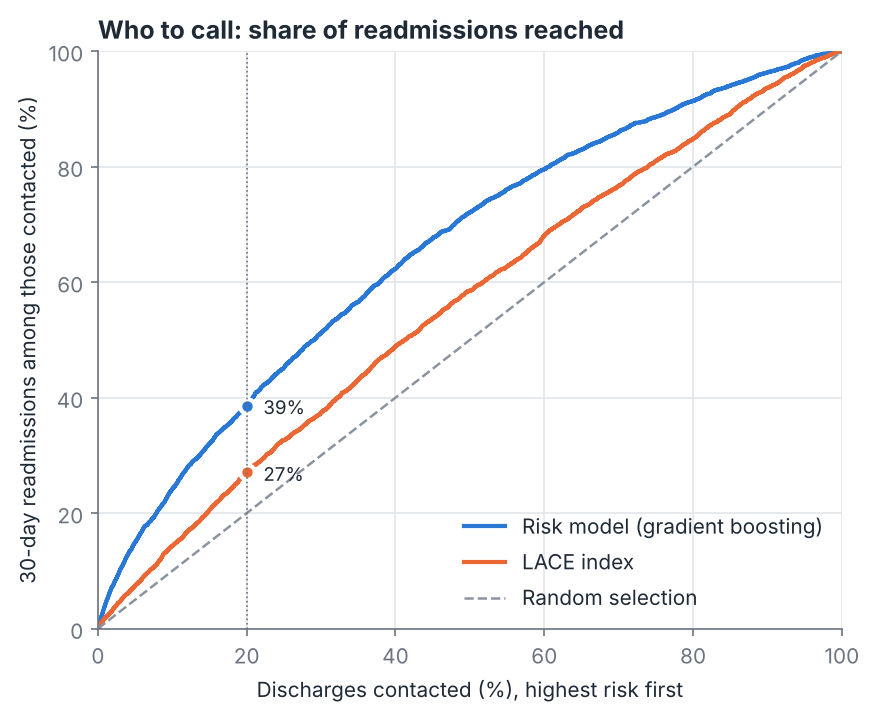

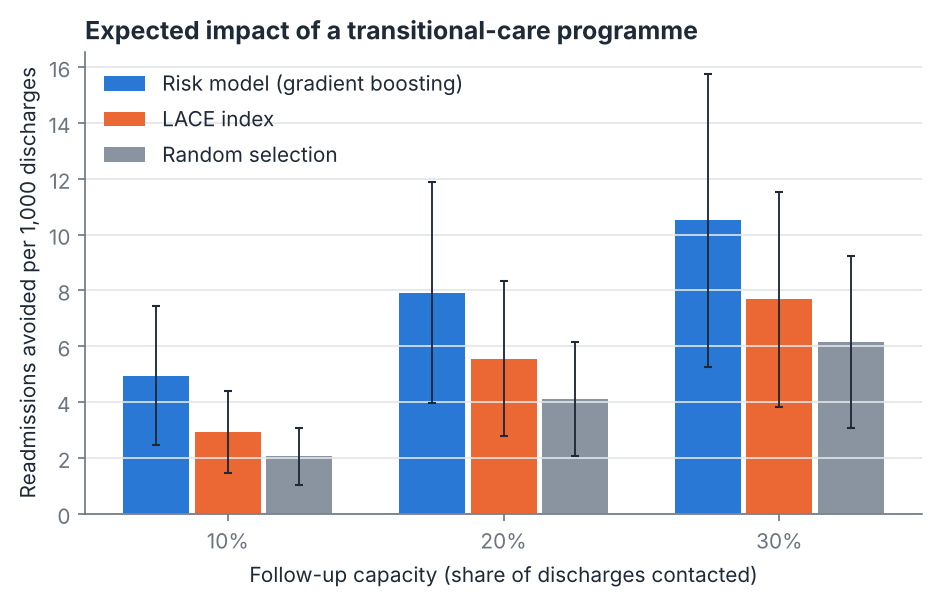

In [8]:
display(Image("../outputs/figures/01_gains_chart.png", width=560))
display(Image("../outputs/figures/02_impact_per_1000.png", width=620))

## 5. Drivers and calibration

In [9]:
pd.read_csv("../outputs/tables/permutation_importance.csv")[["label", "auc_drop"]].head(8)

,label,auc_drop
0,Discharge destination,0.053
1,"Inpatient stays, previous year",0.044
2,Primary diagnosis group,0.007
3,Charlson comorbidity score,0.005
4,"All visits, previous year",0.004
5,Admitting specialty,0.004
6,Diabetes drugs prescribed,0.004
7,Length of stay,0.003


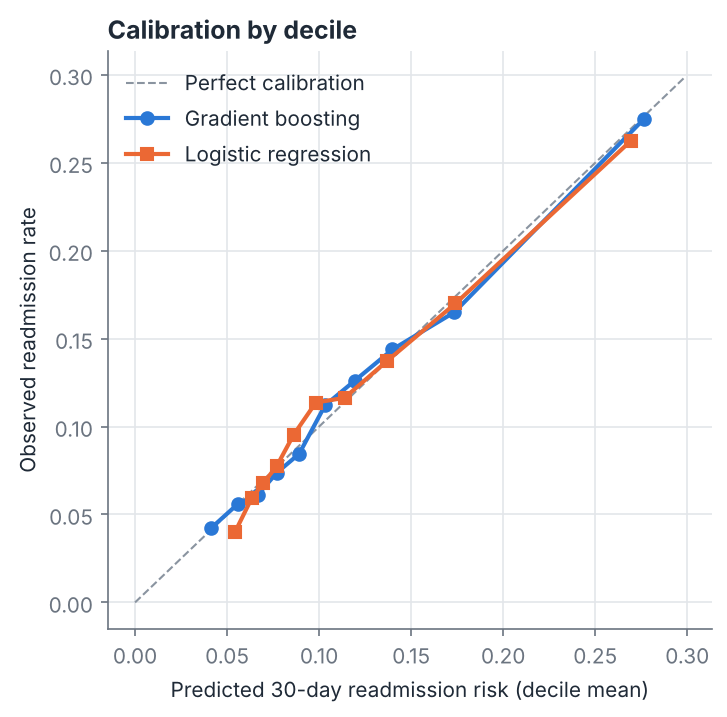

In [10]:
display(Image("../outputs/figures/04_calibration.png", width=460))

## 6. Equity at 20% capacity

Race and gender are not model inputs. This table checks whether outcomes differ by group.

In [11]:
pd.read_csv("../outputs/tables/equity_monitoring.csv")

,attribute,group,encounters,readmission_rate,mean_predicted_risk,share_flagged,readmissions_caught
0,race,AfricanAmerican,5595,0.111,0.114,0.215,0.385
1,race,Asian,217,0.088,0.098,0.120,0.263
2,race,Caucasian,22340,0.116,0.115,0.201,0.392
3,race,Hispanic,608,0.109,0.101,0.155,0.318
4,race,Other,446,0.101,0.098,0.139,0.378
5,race,Unknown,618,0.087,0.099,0.144,0.259
6,gender,Female,16154,0.115,0.118,0.212,0.415
7,gender,Male,13670,0.112,0.110,0.186,0.351
8,age_group,under 50,4793,0.108,0.110,0.195,0.462
9,age_group,50-69,11743,0.108,0.107,0.175,0.370
